# Monthly Milk Production Forecasting with an LSTM

Univariate time-series forecasting of **monthly milk production (1962–1975)** using a Long Short-Term Memory (LSTM) network built with Keras.

**Workflow:** load data → explore & decompose → chronological train/test split → scale → build 12-month sequences → train LSTM → recursive 12-step forecast → evaluate (R²).

> Run this notebook from the `notebooks/` folder so the relative data path resolves.

## 1. Setup

In [ ]:
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

random.seed(42)

## 2. Load the data

The dataset has 168 monthly observations (Jan 1962 – Dec 1975) with a single column, `Production`.

In [ ]:
df = pd.read_csv('../data/monthly_milk_production.csv', index_col='Date', parse_dates=True)
df.head()

,Production
Date,
1962-01-01,589
1962-02-01,561
1962-03-01,640
1962-04-01,656
1962-05-01,727


In [ ]:
len(df)

168

## 3. Exploratory analysis

The series shows a clear **upward trend** and a strong, stable **yearly seasonality**.

<Axes: xlabel='Date'>

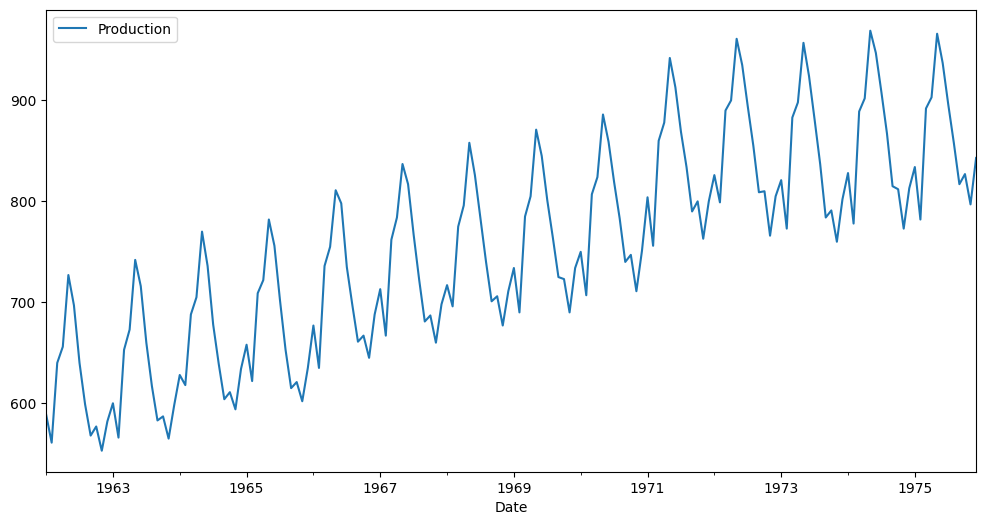

In [ ]:
df.plot(figsize=(12, 6))

### Seasonal decomposition

Splitting the series into trend, seasonal and residual components confirms the 12-month seasonal cycle.

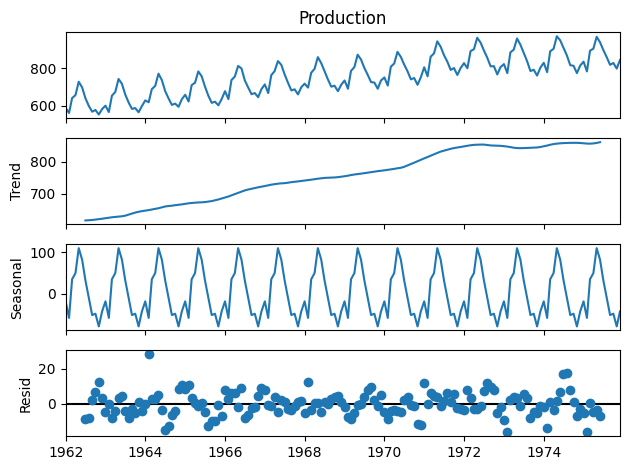

In [ ]:
from statsmodels.tsa.seasonal import seasonal_decompose

results = seasonal_decompose(df['Production'])
results.plot();

## 4. Train / test split

The split is **chronological**: the first 156 months (13 years) are used for training and the last 12 months (1975) are held out for testing. A random split (e.g. `train_test_split`) would leak future information into training and give unrealistically good scores.

In [ ]:
train = df.iloc[:156]
test = df.iloc[156:].copy()

## 5. Scaling

`MinMaxScaler` is **fit on the training data only** and then applied to the test data, so no information from the test period leaks into the scaler.

In [ ]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
scaled_train = scaler.fit_transform(train)
scaled_test = scaler.transform(test)

## 6. Build input sequences

`TimeseriesGenerator` turns the series into (window → next value) training pairs. A small 3-step window first shows how it works; the model itself uses a **12-month window** (one full seasonal cycle).

In [ ]:
from tensorflow.keras.preprocessing.sequence import TimeseriesGenerator

# Demo with a 3-step window
generator = TimeseriesGenerator(scaled_train, scaled_train, length=3, batch_size=1)
x, y = generator[0]
print(f'Given the array:\n{x.flatten()}')
print(f'Predict this y:\n{y}')

In [ ]:
# Actual setup: 12 months of history -> predict the next month
n_input = 12
n_features = 1
generator = TimeseriesGenerator(scaled_train, scaled_train, length=n_input, batch_size=1)

## 7. Model

A single LSTM layer (100 units, `tanh` activation) followed by a one-unit `Dense` output layer, trained with Adam on mean-squared error.

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

model = Sequential()
model.add(LSTM(100, activation='tanh', input_shape=(n_input, n_features)))
model.add(Dense(1))
model.compile(optimizer='adam', loss='mse')

## 8. Training

In [ ]:
model.fit(generator, epochs=100, verbose=0)

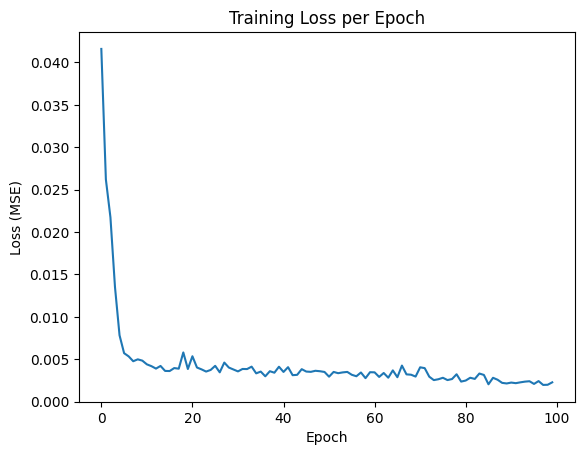

In [ ]:
loss_per_epoch = model.history.history['loss']
plt.plot(range(len(loss_per_epoch)), loss_per_epoch)
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.title('Training Loss per Epoch')
plt.show()

Loss falls quickly in the first few epochs and then flattens, so more epochs would give diminishing returns. There is no validation set here, so overfitting cannot be ruled out from this curve alone — adding a validation split with early stopping is a natural next step.

## 9. Forecast the test period

The model predicts one month ahead. For each step the prediction is **fed back in** as the newest input while the oldest value is dropped (a *recursive* / rolling forecast), so the model forecasts all 12 test months without ever seeing the true test values. Errors can compound over the horizon.

In [ ]:
test_predictions = []

current_batch = scaled_train[-n_input:].reshape((1, n_input, n_features))

for i in range(len(test)):
    current_pred = model.predict(current_batch, verbose=0)[0]
    test_predictions.append(current_pred)
    # slide the window: drop the oldest value, append the new prediction
    current_batch = np.append(current_batch[:, 1:], [[current_pred]], axis=1)

In [ ]:
true_predictions = scaler.inverse_transform(test_predictions)
test['Predictions'] = true_predictions

## 10. Evaluation

In [ ]:
from sklearn.metrics import r2_score

r2 = r2_score(test['Production'], test['Predictions'])
print('R² Score:', r2)

R² Score: 0.7458884014884147


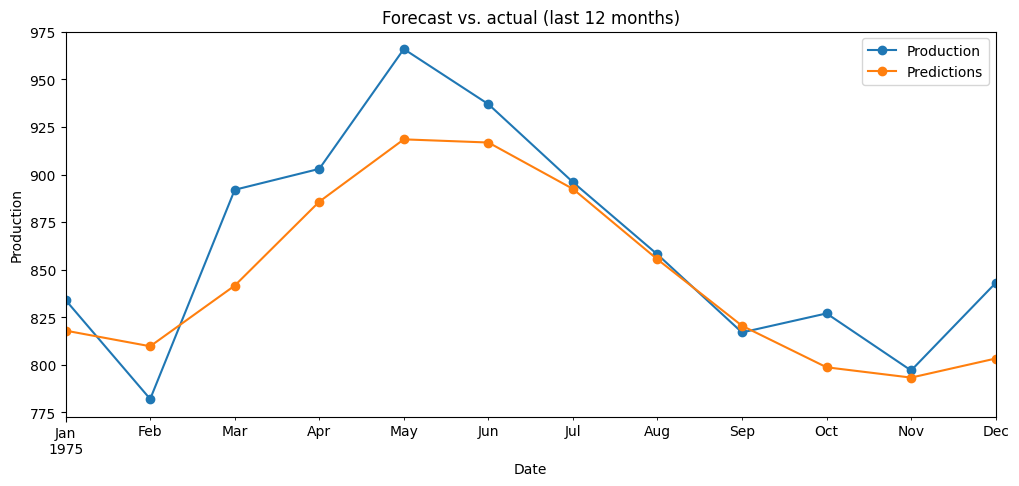

In [ ]:
ax = test[['Production', 'Predictions']].plot(figsize=(12, 5), marker='o',
                                              title='Forecast vs. actual (last 12 months)')
ax.set_ylabel('Production')
plt.show()

**Takeaway:** the LSTM captures the seasonal shape of the held-out year (R² ≈ 0.75) but under-predicts the spring/summer peak and smooths out the sharp early-year dip. Results vary slightly between runs because only Python's `random` module is seeded, not NumPy/TensorFlow.